### Interactive Population Growth Predictor
This notebook demonstrates a population growth model fitted on synthetic population data. You can interactively estimate future populations using the slider or numeric input below.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import ipywidgets as widgets
from ipywidgets import interactive_output, HBox, VBox

# 1. Generate Synthetic Population Data (Year 1950 to 2020)
years = np.arange(1950, 2021, 5)
# Using a logistic-like curve for population growth
# P(t) = L / (1 + exp(-k * (t - t0)))
L_true = 10.0  # Carrying capacity in billions
k_true = 0.03  # Growth rate
t0_true = 1990 # Inflection point

np.random.seed(42)
population_true = L_true / (1 + np.exp(-k_true * (years - t0_true)))
noise = np.random.normal(0, 0.15, len(years))
population_data = np.clip(population_true + noise, 0.5, None)  # Ensure no negative populations

df = pd.DataFrame({'Year': years, 'Population_Billions': population_data})

# 2. Define the Logistic Model Function
def logistic_model(t, L, k, t0):
    return L / (1 + np.exp(-k * (t - t0)))

# Fit the model to our synthetic dataset
p0 = [12.0, 0.02, 2000] # Initial guess
popt, pcov = curve_fit(logistic_model, df['Year'], df['Population_Billions'], p0=p0)
L_fit, k_fit, t0_fit = popt

# 3. Interactive Predictor and Plotting Function
def predict_and_plot(target_year):
    # Calculate prediction
    predicted_pop = logistic_model(target_year, L_fit, k_fit, t0_fit)

    # Generate curve for plotting
    plot_years = np.linspace(1950, max(2100, target_year + 10), 200)
    predicted_curve = logistic_model(plot_years, L_fit, k_fit, t0_fit)

    # Plotting
    plt.figure(figsize=(10, 6))
    plt.scatter(df['Year'], df['Population_Billions'], color='red', zorder=5, label='Historical Data (Synthetic)')
    plt.plot(plot_years, predicted_curve, color='blue', label='Fitted Logistic Growth Model')

    # Highlight prediction point
    plt.scatter(target_year, predicted_pop, color='green', s=120, zorder=6, label=f'Prediction for {target_year}: {predicted_pop:.3f}B')
    plt.axvline(x=target_year, color='gray', linestyle='--', alpha=0.5)
    plt.axhline(y=predicted_pop, color='gray', linestyle='--', alpha=0.5)

    plt.title('Population Growth Projection Model', fontsize=14)
    plt.xlabel('Year', fontsize=12)
    plt.ylabel('Population (Billions)', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper left', fontsize=11)
    plt.xlim(1940, max(2100, target_year + 10))
    plt.ylim(0, L_fit + 2)
    plt.show()

    print(f"Predicted Population in year {target_year}: {predicted_pop:.3f} Billion")

# 4. Create Interactive UI Elements
year_slider = widgets.IntSlider(
    value=2050,
    min=1950,
    max=2150,
    step=1,
    description='Year:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='50%')
)

# Link the widget with our plotting function
out = interactive_output(predict_and_plot, {'target_year': year_slider})

# Display the widgets
display(VBox([year_slider, out]))

### Advanced Resource-Dependent Population Growth Model
This model simulates how a population changes over time based on birth rates, death rates, available resources, and a nation's capability to replenish those resources.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interactive_output, VBox, HBox

def simulate_population(initial_pop, base_birth_rate, base_death_rate, initial_resources, resource_replenish_rate, consumption_rate, shock_year, shock_severity, steps=100):
    # Lists to keep track of history
    pop_history = [initial_pop]
    res_history = [initial_resources]
    years = np.arange(0, steps + 1)

    current_pop = initial_pop
    current_res = initial_resources

    for step_idx in range(steps):
        current_year = step_idx

        # 1. Resource replenishment (Nation's ability to provide)
        current_res += resource_replenish_rate * 10.0

        # 2. Apply sudden resource shock if it matches the shock year
        if current_year == shock_year:
            current_res = current_res * (1.0 - shock_severity)

        # 3. Resource consumption by the population
        total_consumed = current_pop * consumption_rate
        current_res = max(0, current_res - total_consumed)

        # 4. Dynamic death rate based on resource availability per capita
        if current_pop > 0:
            resource_per_capita = current_res / current_pop
        else:
            resource_per_capita = 0

        # If resources per capita are low, death rate climbs
        if resource_per_capita < 1.0:
            # Starvation effect increases death rate up to a cap of 90%
            shortage_factor = 1.0 - resource_per_capita
            actual_death_rate = base_death_rate + shortage_factor * (0.9 - base_death_rate)
        else:
            actual_death_rate = base_death_rate

        # 5. Population update
        births = current_pop * base_birth_rate
        deaths = current_pop * actual_death_rate

        current_pop = max(0.0, current_pop + births - deaths)

        pop_history.append(current_pop)
        res_history.append(current_res)

    return years, np.array(pop_history), np.array(res_history)

def plot_simulation(initial_pop, birth_rate, death_rate, init_res, replenish_rate, shock_year, shock_severity):
    years, pop, res = simulate_population(
        initial_pop=initial_pop,
        base_birth_rate=birth_rate,
        base_death_rate=death_rate,
        initial_resources=init_res,
        resource_replenish_rate=replenish_rate,
        consumption_rate=0.1,
        shock_year=shock_year,
        shock_severity=shock_severity,
        steps=80
    )

    fig, ax1 = plt.subplots(figsize=(12, 6))

    color = 'tab:blue'
    ax1.set_xlabel('Years from Now', fontsize=12)
    ax1.set_ylabel('Population (Millions)', color=color, fontsize=12)
    ax1.plot(years, pop, color=color, linewidth=2.5, label='Population')
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.grid(True, linestyle=':', alpha=0.6)

    ax2 = ax1.twinx()
    color = 'tab:green'
    ax2.set_ylabel('Available Resources (Units)', color=color, fontsize=12)
    ax2.plot(years, res, color=color, linewidth=2, linestyle='--', label='Resources')
    ax2.tick_params(axis='y', labelcolor=color)

    # Visual indicator for the shock event
    if shock_severity > 0 and 0 <= shock_year <= 80:
        plt.axvline(x=shock_year, color='red', linestyle=':', alpha=0.8, label=f'Resource Shock ({int(shock_severity*100)}% loss)')

    plt.title('Interactive Resource-Dependent Population Dynamics (with Resource Shock)', fontsize=14, fontweight='bold')
    fig.tight_layout()
    plt.show()

# Create interactive widgets
style = {'description_width': 'initial'}
layout = widgets.Layout(width='90%')

init_pop_w = widgets.FloatSlider(min=1.0, max=50.0, value=10.0, step=1.0, description='Initial Population (M)', style=style, layout=layout)
birth_rate_w = widgets.FloatSlider(min=0.01, max=0.5, value=0.12, step=0.01, description='Base Birth Rate', style=style, layout=layout)
death_rate_w = widgets.FloatSlider(min=0.01, max=0.5, value=0.05, step=0.01, description='Base Death Rate', style=style, layout=layout)
init_res_w = widgets.FloatSlider(min=10.0, max=500.0, value=100.0, step=10.0, description='Initial Resources', style=style, layout=layout)
replenish_w = widgets.FloatSlider(min=0.0, max=10.0, value=2.0, step=0.5, description='Nation Provision Rate', style=style, layout=layout)

# Shock Parameters
shock_year_w = widgets.IntSlider(min=0, max=80, value=30, description='Shock Year', style=style, layout=layout)
shock_severity_w = widgets.FloatSlider(min=0.0, max=1.0, value=0.0, step=0.05, description='Shock Severity (0-100%)', style=style, layout=layout)

ui = VBox([
    HBox([init_pop_w, init_res_w]),
    HBox([birth_rate_w, death_rate_w]),
    HBox([replenish_w]),
    HBox([shock_year_w, shock_severity_w])
])

out = interactive_output(plot_simulation, {
    'initial_pop': init_pop_w,
    'birth_rate': birth_rate_w,
    'death_rate': death_rate_w,
    'init_res': init_res_w,
    'replenish_rate': replenish_w,
    'shock_year': shock_year_w,
    'shock_severity': shock_severity_w
})

display(ui, out)

Output()

### Section 3: Regression Modeling Comparison
Let's apply standard machine learning/statistical regression techniques (Linear and Polynomial Regression) to fit the historical population data and see how they project future growth.

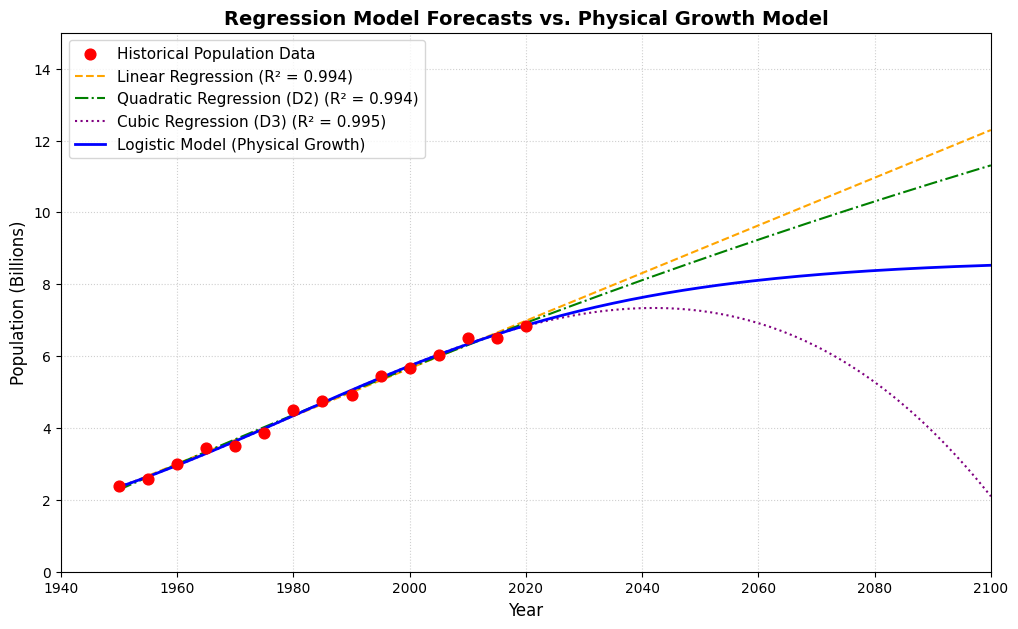

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Prepare training data
X = df[['Year']].values
y = df['Population_Billions'].values

# Generate future years to forecast
future_years = np.arange(1950, 2101, 1).reshape(-1, 1)

# 1. Simple Linear Regression Model
linear_model = LinearRegression()
linear_model.fit(X, y)
y_linear_pred = linear_model.predict(future_years)

# 2. Polynomial Regression Model (Degree 2)
poly_degree_2 = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
poly_degree_2.fit(X, y)
y_poly2_pred = poly_degree_2.predict(future_years)

# 3. Polynomial Regression Model (Degree 3)
poly_degree_3 = make_pipeline(PolynomialFeatures(degree=3), LinearRegression())
poly_degree_3.fit(X, y)
y_poly3_pred = poly_degree_3.predict(future_years)

# Calculate Fit Metrics (on historical data)
r2_linear = r2_score(y, linear_model.predict(X))
r2_poly2 = r2_score(y, poly_degree_2.predict(X))
r2_poly3 = r2_score(y, poly_degree_3.predict(X))

# Plotting the results
plt.figure(figsize=(12, 7))
plt.scatter(X, y, color='red', s=60, zorder=5, label='Historical Population Data')
plt.plot(future_years, y_linear_pred, label=f'Linear Regression (R² = {r2_linear:.3f})', color='orange', linestyle='--')
plt.plot(future_years, y_poly2_pred, label=f'Quadratic Regression (D2) (R² = {r2_poly2:.3f})', color='green', linestyle='-.')
plt.plot(future_years, y_poly3_pred, label=f'Cubic Regression (D3) (R² = {r2_poly3:.3f})', color='purple', linestyle=':')

# Also display logistic model from first section for comparison
y_logistic_pred = logistic_model(future_years.ravel(), L_fit, k_fit, t0_fit)
plt.plot(future_years, y_logistic_pred, label='Logistic Model (Physical Growth)', color='blue', linewidth=2)

plt.title('Regression Model Forecasts vs. Physical Growth Model', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Population (Billions)', fontsize=12)
plt.xlim(1940, 2100)
plt.ylim(0, 15)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

### Section 4: Interpolation Techniques
Let's apply numerical interpolation (Linear and Cubic Spline) on our historical dataset. Interpolation is ideal for estimating values *within* the range of our observed data points (1950 to 2020), unlike regression models which are often used to project or extrapolate far into the future.

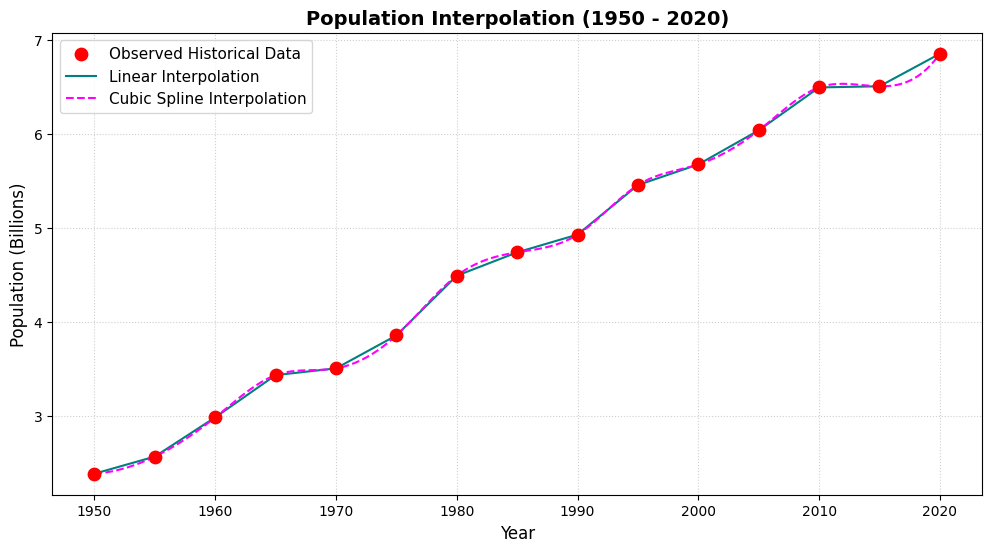

In [4]:
from scipy.interpolate import interp1d

# 1. Extract historical data points
X_observed = df['Year'].values
y_observed = df['Population_Billions'].values

# 2. Define dense range of years for interpolation within the historical boundary [1950, 2020]
interpolation_years = np.linspace(1950, 2020, 300)

# 3. Perform Linear Interpolation
linear_interp = interp1d(X_observed, y_observed, kind='linear')
y_linear_interp = linear_interp(interpolation_years)

# 4. Perform Cubic Spline Interpolation
cubic_interp = interp1d(X_observed, y_observed, kind='cubic')
y_cubic_interp = cubic_interp(interpolation_years)

# Plotting the interpolation results
plt.figure(figsize=(12, 6))
plt.scatter(X_observed, y_observed, color='red', s=80, zorder=5, label='Observed Historical Data')
plt.plot(interpolation_years, y_linear_interp, label='Linear Interpolation', color='teal', linestyle='-')
plt.plot(interpolation_years, y_cubic_interp, label='Cubic Spline Interpolation', color='magenta', linestyle='--')

plt.title('Population Interpolation (1950 - 2020)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Population (Billions)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.show()